In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,RocCurveDisplay

In [3]:
df = pd.read_csv("Bank Customer Churn Prediction.csv")

In [6]:
print(df.head())
print(df.shape)
print(df.info())

   customer_id  credit_score country  gender  age  tenure    balance  \
0     15634602           619  France  Female   42       2       0.00   
1     15647311           608   Spain  Female   41       1   83807.86   
2     15619304           502  France  Female   42       8  159660.80   
3     15701354           699  France  Female   39       1       0.00   
4     15737888           850   Spain  Female   43       2  125510.82   

   products_number  credit_card  active_member  estimated_salary  churn  
0                1            1              1         101348.88      1  
1                1            0              1         112542.58      0  
2                3            1              0         113931.57      1  
3                2            0              0          93826.63      0  
4                1            1              1          79084.10      0  
(10000, 12)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column   

In [13]:
print(df.isnull().sum())
print("duplictes ",df.duplicated().sum())
print(df.describe())

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64
duplictes  0
        customer_id  credit_score           age        tenure        balance  \
count  1.000000e+04  10000.000000  10000.000000  10000.000000   10000.000000   
mean   1.569094e+07    650.528800     38.921800      5.012800   76485.889288   
std    7.193619e+04     96.653299     10.487806      2.892174   62397.405202   
min    1.556570e+07    350.000000     18.000000      0.000000       0.000000   
25%    1.562853e+07    584.000000     32.000000      3.000000       0.000000   
50%    1.569074e+07    652.000000     37.000000      5.000000   97198.540000   
75%    1.575323e+07    718.000000     44.000000      7.000000  127644.240000   
max    1.581569e+07    850.000000     92.000000     10.000000  250898.

churn
0    7963
1    2037
Name: count, dtype: int64


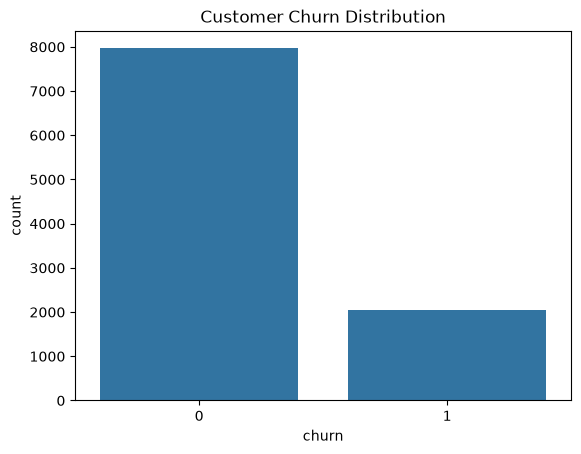

In [14]:
print(df['churn'].value_counts())
sns.countplot(data = df,x='churn')
plt.title("Customer Churn Distribution")
plt.show()

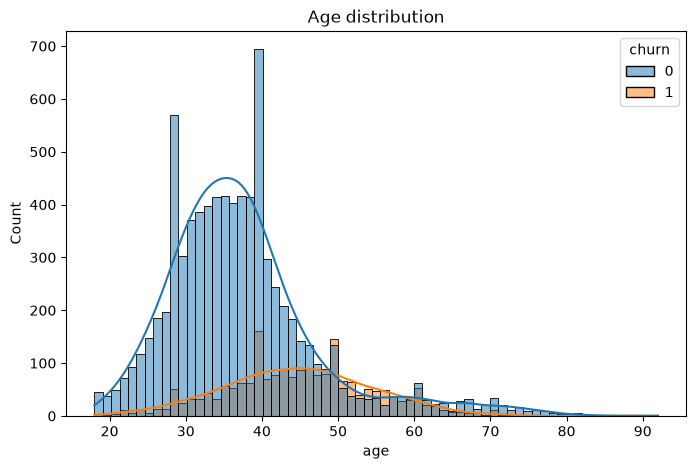

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(data = df,x='age',hue='churn',kde=True)
plt.title("Age distribution")
plt.show()

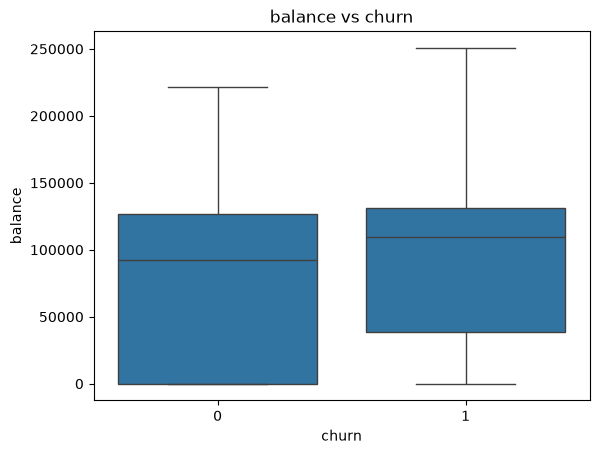

In [16]:
sns.boxplot(data=df,x="churn",y="balance")
plt.title("balance vs churn")
plt.show()

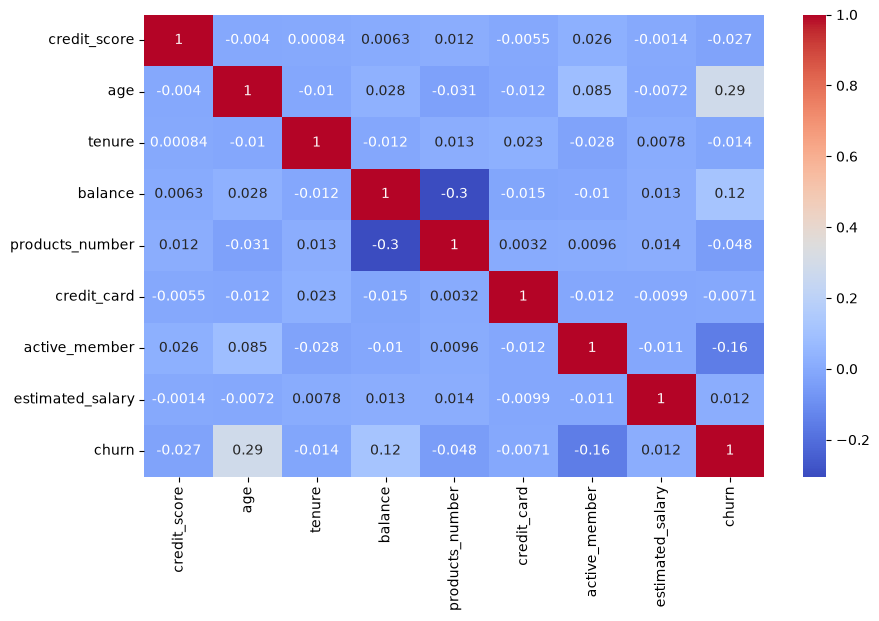

In [19]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include='number').drop(columns=["customer_id"]).corr(),annot = True,cmap='coolwarm')
plt.show()

In [20]:
X = df.drop(['customer_id', 'churn'], axis=1)

y = df['churn']

print(X.head())
print(y.head())

   credit_score country  gender  age  tenure    balance  products_number  \
0           619  France  Female   42       2       0.00                1   
1           608   Spain  Female   41       1   83807.86                1   
2           502  France  Female   42       8  159660.80                3   
3           699  France  Female   39       1       0.00                2   
4           850   Spain  Female   43       2  125510.82                1   

   credit_card  active_member  estimated_salary  
0            1              1         101348.88  
1            0              1         112542.58  
2            1              0         113931.57  
3            0              0          93826.63  
4            1              1          79084.10  
0    1
1    0
2    1
3    0
4    0
Name: churn, dtype: int64


In [24]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)

(8000, 10)
(2000, 10)


In [25]:
categorical = ['country', 'gender']
numerical = ['credit_score', 'age', 'tenure','balance', 'products_number','credit_card', 'active_member','estimated_salary']
preprocessor = ColumnTransformer([('num',StandardScaler(),numerical),('cat',OneHotEncoder(handle_unknown='ignore'),categorical)])

In [26]:
model = Pipeline([('Preprocessing',preprocessor),('Classifier',SVC(kernel='linear'))])
model.fit(X_train,y_train);

In [27]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [28]:
Accuracy = accuracy_score(y_test,y_pred)
print("Accuracy: ",Accuracy)
print(classification_report(y_test,y_pred))

Accuracy:  0.7965
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1593
           1       0.00      0.00      0.00       407

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.63      0.80      0.71      2000



c:\Users\PC\Desktop\PRACTICLES 1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\PRACTICLES 1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\PRACTICLES 1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", res

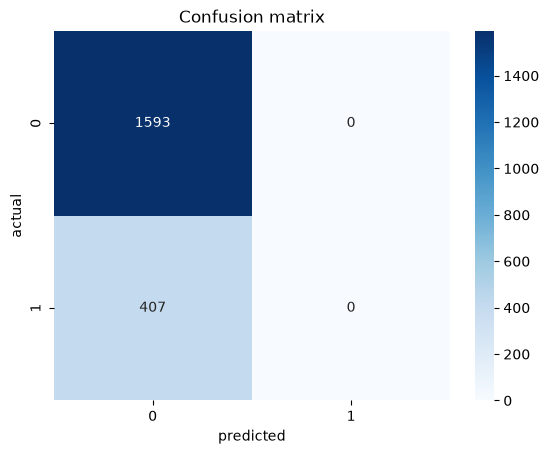

In [31]:
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion matrix")
plt.show()

In [35]:
Kernels = ['linear','poly','rbf','sigmoid']
for k in Kernels:
    svm = Pipeline([('Preprocessing',preprocessor),('classifier',SVC(kernel=k))])
    svm.fit(X_train,y_train)
    pred = svm.predict(X_test)
    print("kernel: ",k)
    print("accuracy: ",accuracy_score(y_test,pred))

kernel:  linear
accuracy:  0.7965
kernel:  poly
accuracy:  0.8595
kernel:  rbf
accuracy:  0.8625
kernel:  sigmoid
accuracy:  0.693


ROC_AUC:  0.6721050788847399


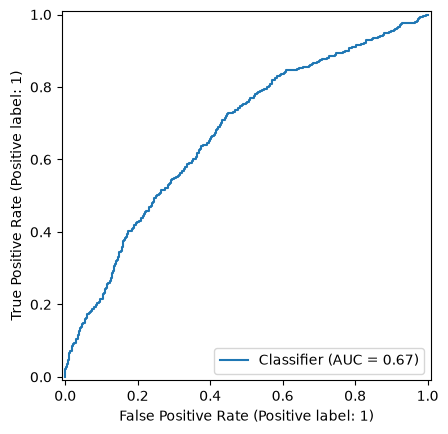

In [39]:
scores = model.decision_function(X_test)
print("ROC_AUC: ",roc_auc_score(y_test,scores))
RocCurveDisplay.from_predictions(y_test,scores)
plt.show()


In [40]:
new_customer = pd.DataFrame([{
    'credit_score': 650,
    'country': 'France',
    'gender': 'Male',
    'age': 35,
    'tenure': 5,
    'balance': 80000,
    'products_number': 2,
    'credit_card': 1,
    'active_member': 1,
    'estimated_salary': 90000
}])

prediction = model.predict(new_customer)

if prediction[0] == 1:
    print("Customer may leave the bank")
else:
    print("Customer may stay with the bank")

Customer may stay with the bank
